In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
from scipy.stats import linregress
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid

In [2]:
#load npz file
mixture_all_cycles = []

#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Mixture.npy.gz', "r")
mixture_all_cycles.append(np.float32(np.load(fn)))

thresh_list = [0.5, 0.75, 0.95, 0.99, 1.0]
for thresh in thresh_list:
    print(thresh)
    if thresh==0.5:
        filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_threshold_flip_booldhsarr_basis_mixture_to0thresh-'+str(thresh)+'_to1thresh'+str(thresh)+'_cycle1_CT20220314.npz'
    elif thresh==1.0:
        filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_threshold_flip_booldhsarr_basis_mixture_to0thresh-'+str(thresh)+'_to1thresh'+str(thresh)+'_cycle1_CT20220321.npz'
    else:
        filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_threshold_flip_booldhsarr_basis_mixture_to0thresh-'+str(thresh)+'_to1thresh'+str(thresh)+'_cycle1_CT20220318.npz'
    cycle_np_file = np.load(filename)
    mixture_all_cycles.append(cycle_np_file['new_decomp_mixture'])

mixture_all_cycles = np.array(mixture_all_cycles)

0.5
0.75
0.95
0.99
1.0


In [3]:
#load npz file
basis_all_cycles = []

#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Basis.npy.gz', "r")
basis_all_cycles.append(np.float32(np.load(fn)))

thresh_list = [0.5, 0.75, 0.95, 0.99, 1.0]
for thresh in thresh_list:
    print(thresh)
    if thresh==0.5:
        filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_threshold_flip_booldhsarr_basis_mixture_to0thresh-'+str(thresh)+'_to1thresh'+str(thresh)+'_cycle1_CT20220314.npz'
    elif thresh==1:
        filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_threshold_flip_booldhsarr_basis_mixture_to0thresh-'+str(thresh)+'_to1thresh'+str(thresh)+'_cycle1_CT20220321.npz'
    else:
        filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_threshold_flip_booldhsarr_basis_mixture_to0thresh-'+str(thresh)+'_to1thresh'+str(thresh)+'_cycle1_CT20220318.npz'
    cycle_np_file = np.load(filename)
    basis_all_cycles.append(cycle_np_file['new_decomp_basis'])

basis_all_cycles = np.array(basis_all_cycles)

0.5
0.75
0.95
0.99
1.0


In [4]:
n_components, n_DHSs = mixture_all_cycles[0].shape

In [5]:
mixture_all_cycles.shape

(6, 16, 3591898)

In [6]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)

#top 10%
DHS_metadata['ind'] = DHS_metadata.index
DHS_metadata_sortby_mean_signal = DHS_metadata.sort_values(['mean_signal'], ascending=False)
top_10_percent_DHSs = DHS_metadata_sortby_mean_signal.iloc[:int(np.round(n_DHSs/10))]
top_10_percent_DHSs_inds = np.array(top_10_percent_DHSs['ind'])
top_10_percent_DHSs_identifiers = np.array(top_10_percent_DHSs['identifier'])

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [7]:
#loading biosample metadata
tsv_file = open("/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_metadata.tsv")
biosample_df = pd.read_csv(tsv_file, delimiter="\t")

In [8]:
#load npz file
# added_delta_all_cycles = []
# removed_delta_all_cycles = []
# added_flat_inds_all_cycles = []
# removed_flat_inds_all_cycles = []

# for i in range(1, 4):
#     filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_threshold_flip_added_removed_delta_flatinds_to0thresh-0.5_to1thresh0.5_cycle'+str(i)+'_CT20220315.npz'
#     cycle_np_file = np.load(filename)
#     added_delta_all_cycles.append(cycle_np_file['added_delta'])
#     removed_delta_all_cycles.append(cycle_np_file['removed_delta'])
#     added_flat_inds_all_cycles.append(cycle_np_file['added_flat_inds'])
#     removed_flat_inds_all_cycles.append(cycle_np_file['removed_flat_inds'])

In [80]:
# filtered_added_delta_all_cycles = []
# filtered_added_flat_inds_all_cycles = []

# for i in range(3):
#     print(i)
#     #when i=0, that is referring to cycle 1 in biosample, DHS, and delta arrays, and we want to compare to 
#     #the previous cycle (original) array value
#     if i==0:
#         #read in 733 sample x 3.5+ million DHS presence/absence matrix
#         dhs_arr = np.load('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy')
        
#     #when i=1, that is referring to cycle 2 in biosample, DHS, and delta arrays, and we want to compare to 
#     #the previous cycle (cycle 1) array value
#     else:
#         filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_threshold_flip_booldhsarr_basis_mixture_to0thresh-0.5_to1thresh0.5_cycle'+str(i)+'_CT20220314.npz'
#         np_file = np.load(filename)
#         dhs_arr = np_file['new_dhs_array']
    
#     n_biosamples, n_DHSs = dhs_arr.shape
    
#     added_flat_inds_single_cycle = []
#     delta_vals_single_cycle = []
    
#     #when i=1, that is referring to cycle 2 in biosample, DHS, and delta arrays, and we want to compare to 
#     #the previous cycle (cycle 1) array value
#     for flat_ind, delta in zip(added_flat_inds_all_cycles[i], added_delta_all_cycles[i]):
#         biosample = flat_ind // n_DHSs
#         dhs = flat_ind % n_DHSs
#         if ~dhs_arr[biosample, dhs]:
#             added_flat_inds_single_cycle.append(flat_ind)
#             delta_vals_single_cycle.append(delta)
    
#     del dhs_arr
#     filtered_added_flat_inds_all_cycles.append(np.array(added_flat_inds_single_cycle))
#     filtered_added_delta_all_cycles.append(np.array(delta_vals_single_cycle))

In [8]:
cycle0_dhs_arr = np.load('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy').astype(int)

**Removed Biosamples**

In [9]:
all_0_biosample_inds = np.where(np.sum(basis_all_cycles, axis=2)==0)

all_0_biosample_inds_50 = all_0_biosample_inds[1][all_0_biosample_inds[0]==1]
all_0_biosample_inds_75 = all_0_biosample_inds[1][all_0_biosample_inds[0]==2]
all_0_biosample_inds_95 = all_0_biosample_inds[1][all_0_biosample_inds[0]==3]
all_0_biosample_inds_99 = all_0_biosample_inds[1][all_0_biosample_inds[0]==4]
all_0_biosample_inds_1 = all_0_biosample_inds[1][all_0_biosample_inds[0]==5]

In [10]:
biosample_df.loc[all_0_biosample_inds_50]

,library order,Biosample name,Vocabulary representative,DCC Experiment ID,DCC Library ID,DCC Biosample ID,Altius Aggregation ID,Altius Library ID,Altius Biosample ID,Replicate indicators,...,Library cleanup,DNaseI units/mL,Amount Nucleic Acid (ng),Nuclei count,Protease inhibitor,Library sequencing date,Reads used,DCC SPOT score,Per-biosample peaks,DHSs in Index
218,219,fHeart,NaN,ENCSR536NGW,ENCLB740GHK,ENCBS312JJA,AG9112,LN3462,DS15839,NaN,...,minElute,80.0,22,4800000.0,A+Sucrose,2010-07-20,24834995,0.4732,17901,17466


In [11]:
np.mean(np.array(biosample_df['DCC SPOT score']))

0.5001987721691677

**How does mean DHS signal change after DHSs are removed each cycle** 

In [12]:
np.sum(mixture_all_cycles, axis=1)[5]

array([0.0016796 , 0.01174812, 0.02572021, ..., 0.03047044, 0.00455358,
       0.00455358], dtype=float32)

In [13]:
not_0_dhs_inds = np.where(np.sum(mixture_all_cycles, axis=1)!=0)

not_0_dhs_inds_50 = not_0_dhs_inds[1][not_0_dhs_inds[0]==1]
not_0_dhs_inds_75 = not_0_dhs_inds[1][not_0_dhs_inds[0]==2]
not_0_dhs_inds_95 = not_0_dhs_inds[1][not_0_dhs_inds[0]==3]
not_0_dhs_inds_99 = not_0_dhs_inds[1][not_0_dhs_inds[0]==4]
not_0_dhs_inds_1 = not_0_dhs_inds[1][not_0_dhs_inds[0]==5]

In [14]:
all_0_dhs_inds = np.where(np.sum(mixture_all_cycles, axis=1)==0)

all_0_dhs_inds_50 = all_0_dhs_inds[1][all_0_dhs_inds[0]==1]
all_0_dhs_inds_75 = all_0_dhs_inds[1][all_0_dhs_inds[0]==2]
all_0_dhs_inds_95 = all_0_dhs_inds[1][all_0_dhs_inds[0]==3]
all_0_dhs_inds_99 = all_0_dhs_inds[1][all_0_dhs_inds[0]==4]
all_0_dhs_inds_1 = all_0_dhs_inds[1][all_0_dhs_inds[0]==5]

In [15]:
print(len(not_0_dhs_inds_50))
print(len(not_0_dhs_inds_75))
print(len(not_0_dhs_inds_95))
print(len(not_0_dhs_inds_99))
print(len(not_0_dhs_inds_1))

763678
1180595
2440129
3330036
3591898


In [16]:
print(len(all_0_dhs_inds_50))
print(len(all_0_dhs_inds_75))
print(len(all_0_dhs_inds_95))
print(len(all_0_dhs_inds_99))
print(len(all_0_dhs_inds_1))

2828220
2411303
1151769
261862
0


In [17]:
print(np.mean(DHS_metadata['mean_signal']))
print(np.mean(DHS_metadata.loc[not_0_dhs_inds_50]['mean_signal']))
print(np.mean(DHS_metadata.loc[not_0_dhs_inds_75]['mean_signal']))
print(np.mean(DHS_metadata.loc[not_0_dhs_inds_95]['mean_signal']))
print(np.mean(DHS_metadata.loc[not_0_dhs_inds_99]['mean_signal']))
print(np.mean(DHS_metadata.loc[not_0_dhs_inds_1]['mean_signal']))

0.6401371981706325
1.264281370497913
1.0401757624719714
0.7265194463980393
0.6359415783620502
0.6401371981706325


In [18]:
comps_for_heatmap = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']

In [19]:
color = ['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3']
neworder = np.array([16,10,7,11,2,12,1,8,4,15,14,5,9,6,3,13]).astype(int) - 1
color = np.array(color)[neworder]

In [20]:
all_0_dhs_inds_99_comps = np.array(DHS_metadata.loc[all_0_dhs_inds_99]['component'])
all_0_dhs_inds_99_comp_nums = []
for comp in comps_for_heatmap:
    all_0_dhs_inds_99_comp_nums.append(len(np.where(all_0_dhs_inds_99_comps==comp)[0]))
all_0_dhs_inds_99_comp_nums = np.array(all_0_dhs_inds_99_comp_nums)

Text(0.5, 1.0, 'Components for DHSs without Biosample Representation in NMF Mixture\nDelta Threshold Flip, Threshold=-0.99/0.99, 1 Cycle')

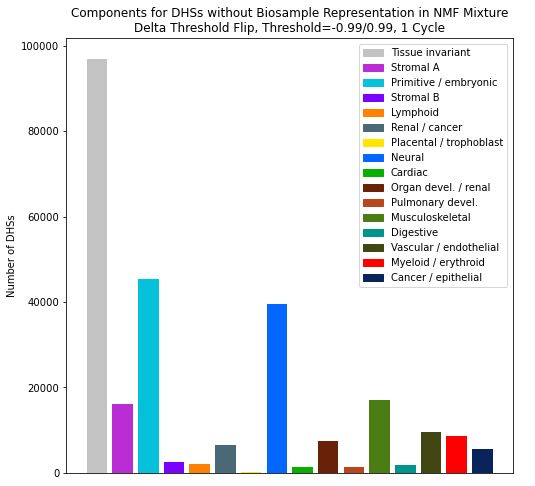

In [21]:
fig = plt.figure(figsize=(8,8))
fig.patch.set_facecolor('white')

plt.bar(comps_for_heatmap, all_0_dhs_inds_99_comp_nums, color=color)
plt.ylabel('Number of DHSs')
plt.xticks([])
handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
fig.legend(handles, comps_for_heatmap, loc = (0.67, 0.41))
plt.title('Components for DHSs without Biosample Representation in NMF Mixture\nDelta Threshold Flip, Threshold=-0.99/0.99, 1 Cycle', fontsize=12)

In [22]:
all_0_dhs_inds_99_df = DHS_metadata.loc[all_0_dhs_inds_99]

all_0_dhs_inds_99_numsamples_comps_binned = []
for comp in comps_for_heatmap:
    all_0_dhs_inds_99_numsamples_binned_per_comp = []
    for i in np.arange(1, 7):
        mask1 = all_0_dhs_inds_99_df['numsamples'].astype(int)==i
        mask2 = all_0_dhs_inds_99_df['component']==comp
        all_0_dhs_inds_99_numsamples_binned_per_comp.append(len(all_0_dhs_inds_99_df[mask1 & mask2]))
    all_0_dhs_inds_99_numsamples_comps_binned.append(all_0_dhs_inds_99_numsamples_binned_per_comp)
all_0_dhs_inds_99_numsamples_comps_binned = np.array(all_0_dhs_inds_99_numsamples_comps_binned)

Text(0.5, 1.0, 'Original Number of Samples for DHSs without Biosample Representation in NMF Mixture, Split by Component\nDelta Threshold Flip, Threshold=-0.99/0.99, 1 Cycle')

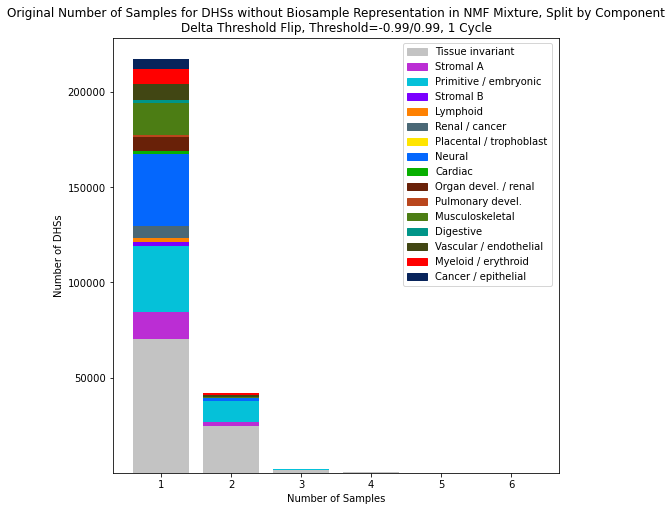

In [23]:
fig = plt.figure(figsize=(8,8))
fig.patch.set_facecolor('white')
b = np.zeros(6)
for ind in range(16):
    plt.bar(np.arange(1, 7), all_0_dhs_inds_99_numsamples_comps_binned[ind, :], bottom=b, color=color[ind])
    b+=all_0_dhs_inds_99_numsamples_comps_binned[ind, :]
handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
fig.legend(handles, comps_for_heatmap, loc = (0.6, 0.44))
plt.ylabel('Number of DHSs')
plt.xlabel('Number of Samples')
plt.xticks(np.arange(1, 7))
plt.title('Original Number of Samples for DHSs without Biosample Representation in NMF Mixture, Split by Component\nDelta Threshold Flip, Threshold=-0.99/0.99, 1 Cycle', fontsize=12)

In [24]:
all_0_dhs_inds_99_numsamples = np.array(DHS_metadata.loc[all_0_dhs_inds_99]['numsamples'].astype(int))

In [25]:
all_0_dhs_inds_99_numsamples_binned = []
for i in np.arange(1, 7):
    all_0_dhs_inds_99_numsamples_binned.append(len(all_0_dhs_inds_99_numsamples[all_0_dhs_inds_99_numsamples==i]))

Text(0.5, 1.0, 'Original Number of Samples for DHSs without Biosample Representation in NMF Mixture\nDelta Threshold Flip, Threshold=-0.99/0.99, 1 Cycle')

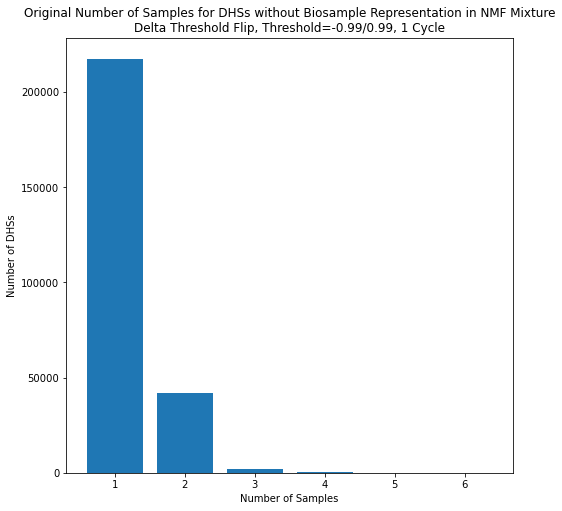

In [26]:
fig = plt.figure(figsize=(8,8))
fig.patch.set_facecolor('white')

plt.bar(np.arange(1, 7), all_0_dhs_inds_99_numsamples_binned)
plt.ylabel('Number of DHSs')
plt.xlabel('Number of Samples')
plt.xticks(np.arange(1, 7))
plt.title('Original Number of Samples for DHSs without Biosample Representation in NMF Mixture\nDelta Threshold Flip, Threshold=-0.99/0.99, 1 Cycle', fontsize=12)

In [27]:
all_0_dhs_inds_99_meansignal = np.array(DHS_metadata.loc[all_0_dhs_inds_99]['mean_signal'])

In [28]:
all_0_dhs_inds_99_sorted_bymeansignal = all_0_dhs_inds_99[np.argsort(-all_0_dhs_inds_99_meansignal)]

In [29]:
all_0_dhs_inds_99_sorted_bymeansignal_df = DHS_metadata.loc[all_0_dhs_inds_99_sorted_bymeansignal]
all_0_dhs_inds_99_sorted_bymeansignal_chrm = np.array(all_0_dhs_inds_99_sorted_bymeansignal_df['seqname'])
all_0_dhs_inds_99_sorted_bymeansignal_start = np.array(all_0_dhs_inds_99_sorted_bymeansignal_df['start'])
all_0_dhs_inds_99_sorted_bymeansignal_end = np.array(all_0_dhs_inds_99_sorted_bymeansignal_df['end'])
all_0_dhs_inds_99_sorted_bymeansignal_mean_signal = np.array(all_0_dhs_inds_99_sorted_bymeansignal_df['mean_signal'])

In [322]:
today = date.today()
bed_path_name = os.path.join('/home/ctrader/public_html/', 'NMF_delta_threshold_flip_99thresh_top_100_mean_signal_removed_DHSs_cycle1_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(100):
    f.write(str(all_0_dhs_inds_99_sorted_bymeansignal_chrm[i]) + '\t' + str(all_0_dhs_inds_99_sorted_bymeansignal_start[i]) + '\t' + str(all_0_dhs_inds_99_sorted_bymeansignal_end[i]) + '\t' + str(all_0_dhs_inds_99_sorted_bymeansignal_mean_signal[i]) + '\n')
f.close()
link_path = 'https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + 'NMF_delta_threshold_flip_99thresh_top_100_mean_signal_removed_DHSs_cycle1_CT' + today.strftime("%Y%m%d") + '.bed'
print(link_path)

https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_delta_threshold_flip_99thresh_top_100_mean_signal_removed_DHSs_cycle1_CT20220321.bed


In [330]:
DHS_metadata.loc[all_0_dhs_inds_99_sorted_bymeansignal[40000:40100]]

,seqname,start,end,identifier,mean_signal,numsamples,summit,core_start,core_end,component,ind
2048354,chr22,36029275,36029345,22.737685,1.106270,1,36029290,36029290.0,36029290.0,Stromal A,2048354
2609165,chr5,80133640,80133820,5.497353,1.106259,2,80133730,80133730.0,80133730.0,Primitive / embryonic,2609165
44881,chr1,26506880,26507040,1.195842,1.106235,2,26506980,26506970,26506990,Tissue invariant,44881
1414234,chr18,9596192,9596248,18.207423,1.106190,1,9596248,9596248.0,9596248.0,Musculoskeletal,1414234
2626829,chr5,96714860,96715078,5.5794795,1.106190,1,96714950,96714950.0,96714950.0,Musculoskeletal,2626829
...,...,...,...,...,...,...,...,...,...,...,...
2651132,chr5,120405860,120405883,5.696966,1.103630,1,120405883,120405883.0,120405883.0,Stromal A,2651132
189781,chr1,158146660,158146864,1.67159,1.103630,1,158146750,158146750.0,158146750.0,Stromal A,189781
2636293,chr5,107325997,107326073,5.632086,1.103630,1,107326050,107326050.0,107326050.0,Stromal A,2636293
3540164,chrX,100685372,100685425,X.680682,1.103630,1,100685373,100685373.0,100685373.0,Stromal A,3540164


In [331]:
all_0_dhs_inds_99_sorted_bymeansignal_df = DHS_metadata.loc[all_0_dhs_inds_99_sorted_bymeansignal[40000:40100]]
all_0_dhs_inds_99_sorted_bymeansignal_chrm = np.array(all_0_dhs_inds_99_sorted_bymeansignal_df['seqname'])
all_0_dhs_inds_99_sorted_bymeansignal_start = np.array(all_0_dhs_inds_99_sorted_bymeansignal_df['start'])
all_0_dhs_inds_99_sorted_bymeansignal_end = np.array(all_0_dhs_inds_99_sorted_bymeansignal_df['end'])
all_0_dhs_inds_99_sorted_bymeansignal_mean_signal = np.array(all_0_dhs_inds_99_sorted_bymeansignal_df['mean_signal'])

In [332]:
today = date.today()
bed_path_name = os.path.join('/home/ctrader/public_html/', 'NMF_delta_threshold_flip_99thresh_midtier_mean_signal_removed_DHSs_cycle1_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(100):
    f.write(str(all_0_dhs_inds_99_sorted_bymeansignal_chrm[i]) + '\t' + str(all_0_dhs_inds_99_sorted_bymeansignal_start[i]) + '\t' + str(all_0_dhs_inds_99_sorted_bymeansignal_end[i]) + '\t' + str(all_0_dhs_inds_99_sorted_bymeansignal_mean_signal[i]) + '\n')
f.close()
link_path = 'https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + 'NMF_delta_threshold_flip_99thresh_midtier_mean_signal_removed_DHSs_cycle1_CT' + today.strftime("%Y%m%d") + '.bed'
print(link_path)

https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_delta_threshold_flip_99thresh_midtier_mean_signal_removed_DHSs_cycle1_CT20220321.bed


In [306]:
b = [0.005, 0.01, 0.05, 0.1, 0.5, 1, 5, 10, 50, 100, 500]
data = all_0_dhs_inds_99_meansignal
all_0_dhs_inds_99_meansignal_binned = []
for i in range(len(b)-1):
    all_0_dhs_inds_99_meansignal_binned.append(len(data[(data>=b[i]) & (data<b[i+1])]))

Text(0.5, 1.0, 'Mean Signal for DHSs without Biosample Representation in NMF Mixture\nDelta Threshold Flip, Threshold=-0.99/0.99, 1 Cycle')

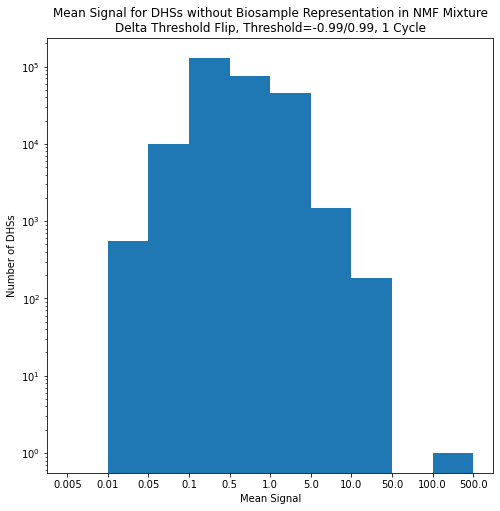

In [309]:
fig = plt.figure(figsize=(8,8))
fig.patch.set_facecolor('white')

plt.bar(np.arange(len(all_0_dhs_inds_99_meansignal_binned)), 
              all_0_dhs_inds_99_meansignal_binned, 
              align='edge',
              width=1)
plt.yscale('log')
# plt.ylim([1e-6, 1])
plt.xticks(np.arange(len(all_0_dhs_inds_99_meansignal_binned)+1), 
           np.array(b).astype(str))
plt.ylabel('Number of DHSs')
plt.xlabel('Mean Signal')
plt.title('Mean Signal for DHSs without Biosample Representation in NMF Mixture\nDelta Threshold Flip, Threshold=-0.99/0.99, 1 Cycle', fontsize=12)

**Top 10% DHSs for each Mixture**

In [23]:
#quantitatively comparing mixture embeddings
mixture_all_cycles_10per = mixture_all_cycles[:, :, top_10_percent_DHSs_inds]

**Top comp of basis and top 10% mixtures**

In [24]:
#top comps
mixture_all_cycles_10per_top_comp = np.argmax(mixture_all_cycles_10per, axis=1)
mixture_all_cycles_10per_top_comp_val = np.max(mixture_all_cycles_10per, axis=1)

#sum
mixture_all_cycles_10per_sum = np.sum(mixture_all_cycles_10per, axis=1)

In [25]:
mixture_all_cycles_10per_top_comp_notall0 = np.where(mixture_all_cycles_10per_sum==0, 
                                                     np.nan, 
                                                     mixture_all_cycles_10per_top_comp)

mixture_all_cycles_10per_top_comp_val_notall0 = np.where(mixture_all_cycles_10per_sum==0, 
                                                         np.nan, 
                                                         mixture_all_cycles_10per_top_comp_val)

mixture_all_cycles_10per[np.where(mixture_all_cycles_10per_sum==0)[0],
                         :, 
                         np.where(mixture_all_cycles_10per_sum==0)[1]]=np.nan

In [26]:
#top comps
basis_all_cycles_top_comp = np.argmax(basis_all_cycles, axis=2)
basis_all_cycles_top_comp_val = np.max(basis_all_cycles, axis=2)

#sum
basis_all_cycles_sum = np.sum(basis_all_cycles, axis=2)

In [27]:
basis_all_cycles_top_comp_notall0 = np.where(basis_all_cycles_sum==0, 
                                             np.nan, 
                                             basis_all_cycles_top_comp)

basis_all_cycles_top_comp_val_notall0 = np.where(basis_all_cycles_sum==0, 
                                                 np.nan, 
                                                 basis_all_cycles_top_comp_val)

basis_all_cycles[np.where(basis_all_cycles_sum==0)[0],
                 np.where(basis_all_cycles_sum==0)[1],
                 :]=np.nan

**Mixture (top 10%) and Basis Purity**

In [28]:
#top 10% DHSs
mixture_all_cycles_10per_top_comp_val = np.nanmax(mixture_all_cycles_10per, axis=1)
mixture_all_cycles_10per_nansum = np.nansum(mixture_all_cycles_10per, axis=1)

mixture_all_cycles_10per_pur_by_sum = mixture_all_cycles_10per_top_comp_val / mixture_all_cycles_10per_nansum

/tmp/ipykernel_124213/2851208689.py:2: RuntimeWarning: All-NaN slice encountered
  mixture_all_cycles_10per_top_comp_val = np.nanmax(mixture_all_cycles_10per, axis=1)


In [29]:
basis_all_cycles_top_comp_val = np.nanmax(basis_all_cycles, axis=2)
basis_all_cycles_nansum = np.nansum(basis_all_cycles, axis=2)

basis_all_cycles_pur_by_sum = basis_all_cycles_top_comp_val / basis_all_cycles_nansum

/tmp/ipykernel_124213/603180168.py:1: RuntimeWarning: All-NaN slice encountered
  basis_all_cycles_top_comp_val = np.nanmax(basis_all_cycles, axis=2)


Text(0.5, 1.07, 'NMF Loading Purity (by Top Component Value/Sum of Components)\nDelta Threshold Flip, 1 Cycle')

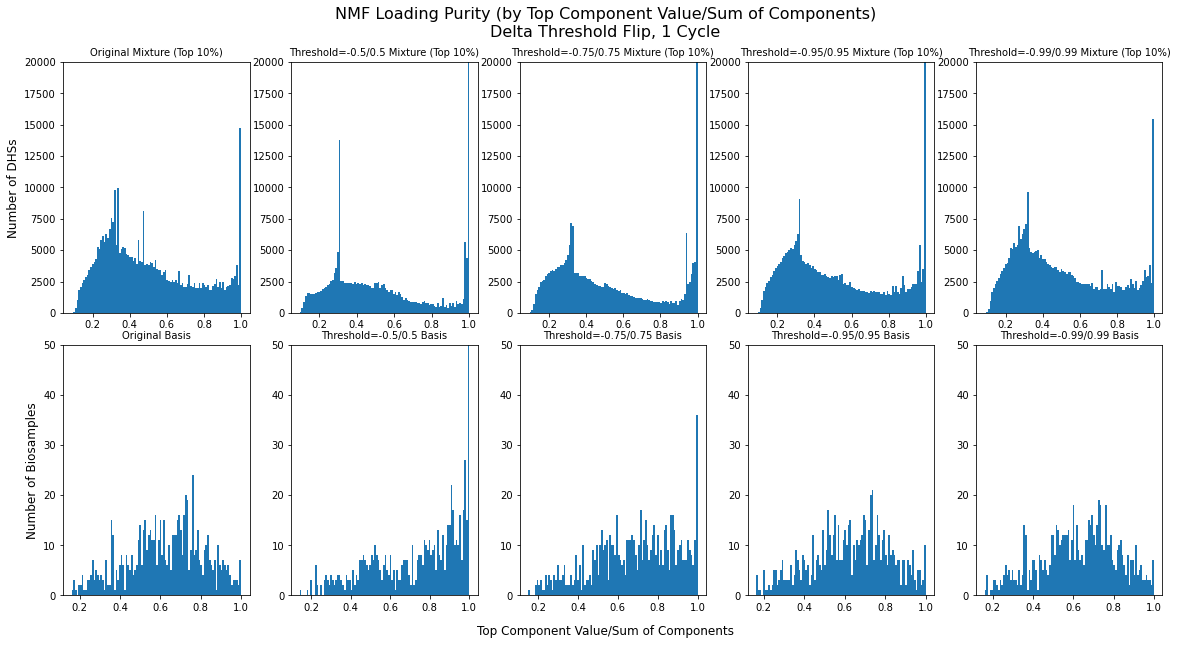

In [30]:
fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(16,8))
fig.patch.set_facecolor('white')
fig.tight_layout()

thresh_name_list = ['Original', 'Threshold=-0.5/0.5', 'Threshold=-0.75/0.75', 'Threshold=-0.95/0.95', 'Threshold=-0.99/0.99']

axes = axes.ravel()
for ind in range(5):
    axes[ind].hist(mixture_all_cycles_10per_pur_by_sum[ind], bins=100)
    axes[ind+5].hist(basis_all_cycles_pur_by_sum[ind], bins=100)
    axes[ind].set_ylim([0, 20000])#70000
    axes[ind+5].set_ylim([0, 50])#500
    axes[ind].set_title(thresh_name_list[ind]+' Mixture (Top 10%)', fontsize=10)
    axes[ind+5].set_title(thresh_name_list[ind]+' Basis', fontsize=10)

axes[0].set_ylabel('Number of DHSs', fontsize=12)
axes[5].set_ylabel('Number of Biosamples', fontsize=12)
fig.text(0.5, -0.02, 'Top Component Value/Sum of Components', ha='center', fontsize=12)
plt.suptitle('NMF Loading Purity (by Top Component Value/Sum of Components)\nDelta Threshold Flip, 1 Cycle', fontsize=16, x=0.5, y=1.07)

In [35]:
#finding the number of comps it takes to make up 50% of loading sum
threshold = 0.5
basis_purity_count_all_cycles = []
for cycle in range(5):
    count_per_cycle = []
    for biosample in range(len(basis_all_cycles[0, :, 0])):
        loading_sum = basis_all_cycles_nansum[cycle, biosample]
        loading = basis_all_cycles[cycle, biosample, :]
        loading_sorted = -np.sort(-loading)
        count = 0
        running_sum = 0
        while running_sum < (threshold * loading_sum):
            running_sum += loading_sorted[count]
            count += 1
        count_per_cycle.append(count)
    basis_purity_count_all_cycles.append(count_per_cycle)
basis_purity_count_all_cycles = np.array(basis_purity_count_all_cycles)

In [36]:
#finding the number of comps it takes to make up 50% of loading sum
threshold = 0.5
mixture_purity_count_all_cycles_10per = []
for cycle in range(5):
    count_per_cycle = []
    for dhs in range(len(mixture_all_cycles_10per[0, 0, :])):
        loading_sum = mixture_all_cycles_10per_nansum[cycle, dhs]
        loading = mixture_all_cycles_10per[cycle, :, dhs]
        loading_sorted = -np.sort(-loading)
        count = 0
        running_sum = 0
        while running_sum < (threshold * loading_sum):
            running_sum += loading_sorted[count]
            count += 1
        count_per_cycle.append(count)
    mixture_purity_count_all_cycles_10per.append(count_per_cycle)
mixture_purity_count_all_cycles_10per = np.array(mixture_purity_count_all_cycles_10per)

In [37]:
for i in basis_purity_count_all_cycles:
    print(np.min(i))

1
0
1
1
1


Text(0.5, 1.07, 'NMF Loading Purity (by Number of Components Making Up 50% of Loading Sum)\nDelta Threshold Flip, 1 Cycle')

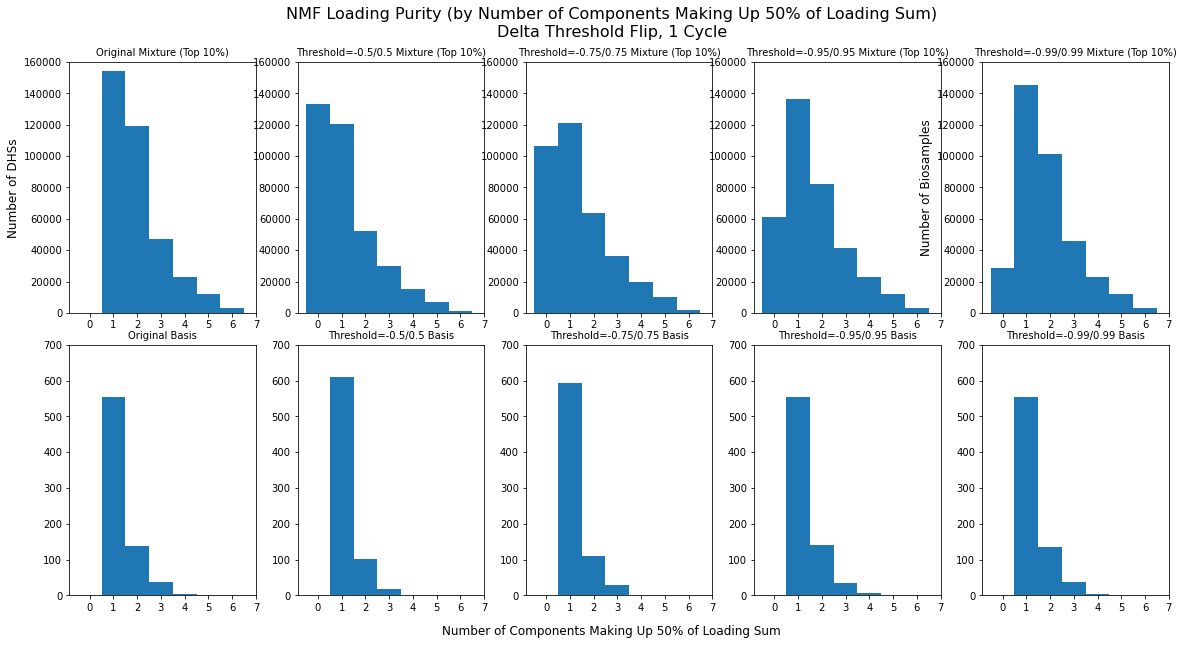

In [38]:
fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(16,8))
fig.patch.set_facecolor('white')
fig.tight_layout()

thresh_name_list = ['Original', 'Threshold=-0.5/0.5', 'Threshold=-0.75/0.75', 'Threshold=-0.95/0.95', 'Threshold=-0.99/0.99']

axes = axes.ravel()
for ind in range(5):
    axes[ind].hist(mixture_purity_count_all_cycles_10per[ind], width=1, align='left', bins=[0, 1, 2, 3, 4, 5, 6, 7])
    axes[ind+5].hist(basis_purity_count_all_cycles[ind], width=1, align='left', bins=[0, 1, 2, 3, 4, 5, 6, 7])
    axes[ind].set_ylim([0, 160000])#70000
    axes[ind+5].set_ylim([0, 700])#500
    axes[ind].set_title(thresh_name_list[ind]+' Mixture (Top 10%)', fontsize=10)
    axes[ind+5].set_title(thresh_name_list[ind]+' Basis', fontsize=10)
    axes[ind].set_xticks([0, 1, 2, 3, 4, 5, 6, 7])
    axes[ind+5].set_xticks([0, 1, 2, 3, 4, 5, 6, 7])
#     axes[ind].set_xlim([0, 7])
#     axes[ind+4].set_xlim([0, 7])

axes[0].set_ylabel('Number of DHSs', fontsize=12)
axes[4].set_ylabel('Number of Biosamples', fontsize=12)
fig.text(0.5, -0.02, 'Number of Components Making Up 50% of Loading Sum', ha='center', fontsize=12)
plt.suptitle('NMF Loading Purity (by Number of Components Making Up 50% of Loading Sum)\nDelta Threshold Flip, 1 Cycle', fontsize=16, x=0.5, y=1.07)